# EXPT NO: 8
# TRAIN A SIMPLE AUTOENCODER FOR DIMENSIONALITY REDUCTION AND FEATURE LEARNING

**Student Roll No:** 24BAD108  


# PART A – DATASET PREPARATION AND PREPROCESSING



In [1]:
# Cell 1: Import libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import mnist
from tensorflow.keras import layers, Model

np.random.seed(42)
tf.random.set_seed(42)

print("TensorFlow version:", tf.__version__)
print("Libraries imported successfully.")


TensorFlow version: 2.21.0
Libraries imported successfully.


In [2]:
# Cell 2: Load MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

print("Training images:", x_train.shape)
print("Testing images :", x_test.shape)
print("Image dimensions:", x_train.shape[1:])


11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images: (60000, 28, 28)
Testing images : (10000, 28, 28)
Image dimensions: (28, 28)


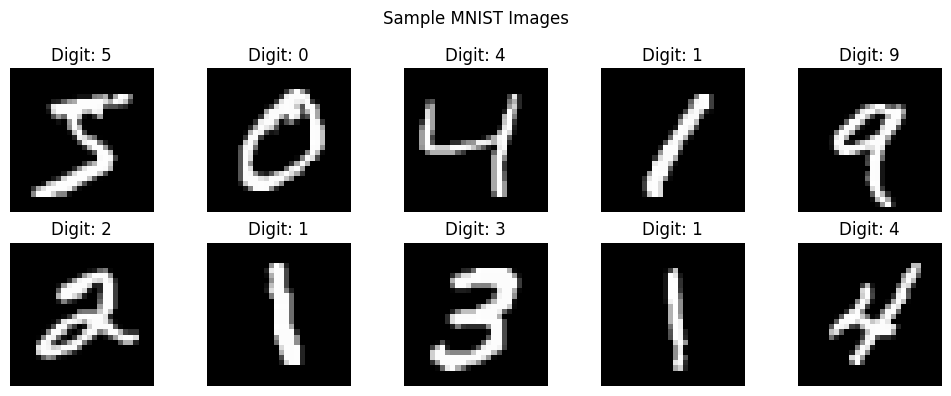

In [3]:
# Cell 3: Display sample images
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap="gray")
    plt.title(f"Digit: {y_train[i]}")
    plt.axis("off")
plt.suptitle("Sample MNIST Images")
plt.tight_layout()
plt.show()


In [4]:
# Cell 4: Normalize pixel values and flatten images
# Convert pixel values from [0, 255] to [0, 1]
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

# Flatten each 28 x 28 image into a 784-dimensional vector
x_train_flat = x_train.reshape(len(x_train), 784)
x_test_flat = x_test.reshape(len(x_test), 784)

print("Flattened training data:", x_train_flat.shape)
print("Flattened testing data :", x_test_flat.shape)
print("Minimum pixel value:", x_train_flat.min())
print("Maximum pixel value:", x_train_flat.max())


Flattened training data: (60000, 784)
Flattened testing data : (10000, 784)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


# PART B – IMPLEMENTING THE ENCODER AND DECODER



In [5]:
# Cell 5: Build the Encoder
INPUT_DIM = 784
LATENT_DIM = 32

encoder_input = layers.Input(shape=(INPUT_DIM,), name="encoder_input")
x = layers.Dense(128, activation="relu", name="encoder_dense_1")(encoder_input)
x = layers.Dense(64, activation="relu", name="encoder_dense_2")(x)
latent_vector = layers.Dense(LATENT_DIM, activation="relu", name="latent_vector")(x)

encoder = Model(encoder_input, latent_vector, name="encoder")
encoder.summary()


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ encoder_input (InputLayer)      │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_1 (Dense)         │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder_dense_2 (Dense)         │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent_vector (Dense)           │ (None, 32)             │         2,080 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 110,816 (432.88 KB)

 Trainable params: 110,816 (432.88 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Cell 6: Build the Decoder
decoder_input = layers.Input(shape=(LATENT_DIM,), name="decoder_input")
x = layers.Dense(64, activation="relu", name="decoder_dense_1")(decoder_input)
x = layers.Dense(128, activation="relu", name="decoder_dense_2")(x)
decoder_output = layers.Dense(INPUT_DIM, activation="sigmoid", name="reconstructed_output")(x)

decoder = Model(decoder_input, decoder_output, name="decoder")
decoder.summary()


Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ decoder_input (InputLayer)      │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_1 (Dense)         │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder_dense_2 (Dense)         │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstructed_output (Dense)    │ (None, 784)            │       101,136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,568 (435.81 KB)

 Trainable params: 111,568 (435.81 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# Cell 7: Combine Encoder and Decoder into an Autoencoder
autoencoder_input = layers.Input(shape=(INPUT_DIM,), name="autoencoder_input")
encoded = encoder(autoencoder_input)
reconstructed = decoder(encoded)

autoencoder = Model(autoencoder_input, reconstructed, name="autoencoder")
autoencoder.summary()


Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ autoencoder_input (InputLayer)  │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ encoder (Functional)            │ (None, 32)             │       110,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ decoder (Functional)            │ (None, 784)            │       111,568 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 222,384 (868.69 KB)

 Trainable params: 222,384 (868.69 KB)

 Non-trainable params: 0 (0.00 B)

# PART C – COMPILING AND TRAINING THE AUTOENCODER



In [8]:
# Cell 8: Compile the autoencoder
autoencoder.compile(optimizer="adam", loss="binary_crossentropy")
print("Autoencoder compiled successfully.")


Autoencoder compiled successfully.


In [9]:
# Cell 9: Train the autoencoder
EPOCHS = 10
BATCH_SIZE = 256

history = autoencoder.fit(
    x_train_flat,
    x_train_flat,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    shuffle=True,
    validation_data=(x_test_flat, x_test_flat),
    verbose=1
)


Epoch 1/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 11s 27ms/step - loss: 0.2396 - val_loss: 0.1641
Epoch 2/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 20ms/step - loss: 0.1481 - val_loss: 0.1350
Epoch 3/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.1299 - val_loss: 0.1232
Epoch 4/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 26ms/step - loss: 0.1215 - val_loss: 0.1169
Epoch 5/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.1156 - val_loss: 0.1117
Epoch 6/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 24ms/step - loss: 0.1111 - val_loss: 0.1077
Epoch 7/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 5s 22ms/step - loss: 0.1075 - val_loss: 0.1047
Epoch 8/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.1046 - val_loss: 0.1023
Epoch 9/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - loss: 0.1024 - val_loss: 0.1003
Epoch 10/10
235/235 ━━━━━━━━━━━━━━━━━━━━ 4s 19ms/step - loss: 0.1006 - val_loss: 0.0988


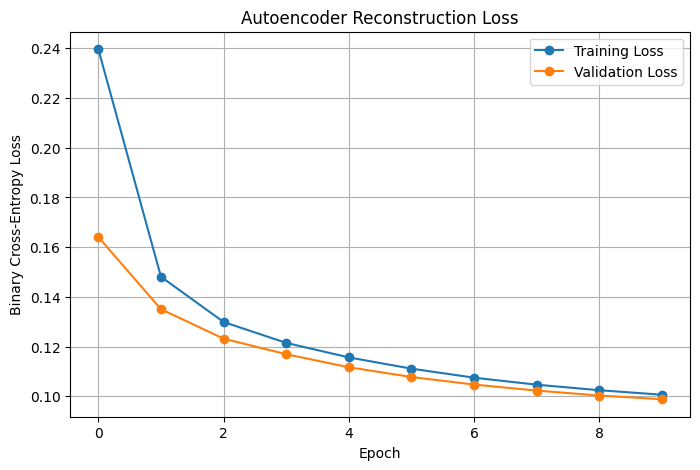

In [10]:
# Cell 10: Plot training and validation loss
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss", marker="o")
plt.plot(history.history["val_loss"], label="Validation Loss", marker="o")
plt.title("Autoencoder Reconstruction Loss")
plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.legend()
plt.grid(True)
plt.show()


In [11]:
# Cell 11: Evaluate reconstruction loss on test data
test_loss = autoencoder.evaluate(x_test_flat, x_test_flat, verbose=0)
print("Test Reconstruction Loss:", test_loss)


Test Reconstruction Loss: 0.09878864139318466


# PART D – DIMENSIONALITY REDUCTION, FEATURE LEARNING AND RECONSTRUCTION


In [12]:
# Cell 12: Extract latent features
latent_features = encoder.predict(x_test_flat, batch_size=BATCH_SIZE, verbose=1)

print("Original feature dimension:", x_test_flat.shape[1])
print("Latent feature dimension  :", latent_features.shape[1])
print("Latent feature matrix shape:", latent_features.shape)


40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
Original feature dimension: 784
Latent feature dimension  : 32
Latent feature matrix shape: (10000, 32)


In [13]:
# Cell 13: Reconstruct test images
reconstructed_images = autoencoder.predict(x_test_flat[:10], verbose=0)
reconstructed_images = reconstructed_images.reshape(-1, 28, 28)
print("Reconstructed image shape:", reconstructed_images.shape)


Reconstructed image shape: (10, 28, 28)


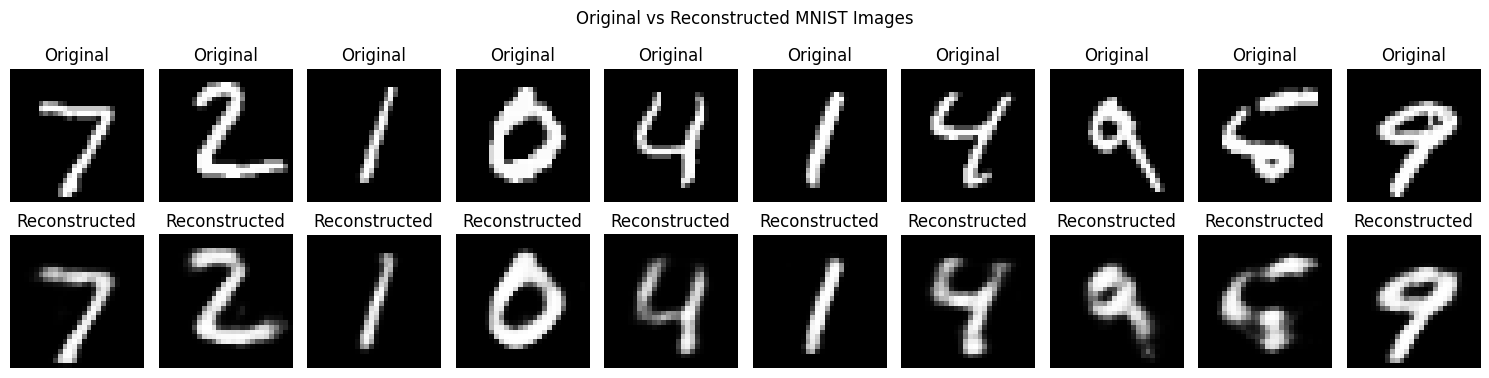

In [14]:
# Cell 14: Display original and reconstructed images
n = 10
plt.figure(figsize=(15, 4))
for i in range(n):
    plt.subplot(2, n, i + 1)
    plt.imshow(x_test[i], cmap="gray")
    plt.title("Original")
    plt.axis("off")

    plt.subplot(2, n, n + i + 1)
    plt.imshow(reconstructed_images[i], cmap="gray")
    plt.title("Reconstructed")
    plt.axis("off")

plt.suptitle("Original vs Reconstructed MNIST Images")
plt.tight_layout()
plt.show()


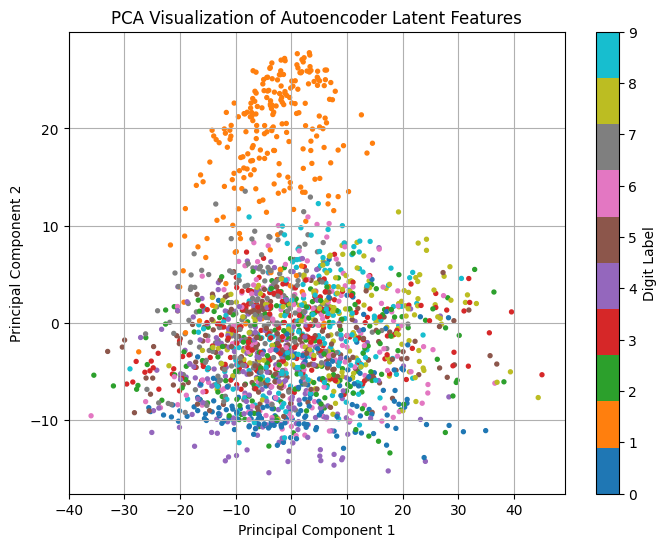

Explained variance ratio: [0.32793102 0.17102444]


In [15]:
# Cell 15: Optional 2D visualization of latent features using PCA
from sklearn.decomposition import PCA

VIS_SAMPLES = 2000
pca = PCA(n_components=2, random_state=42)
latent_2d = pca.fit_transform(latent_features[:VIS_SAMPLES])

plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    latent_2d[:, 0], latent_2d[:, 1],
    c=y_test[:VIS_SAMPLES], cmap="tab10", s=8
)
plt.title("PCA Visualization of Autoencoder Latent Features")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.colorbar(scatter, label="Digit Label")
plt.grid(True)
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)


In [16]:
# Cell 16: Save the trained model and outputs
autoencoder.save("mnist_autoencoder.keras")
encoder.save("mnist_encoder.keras")
decoder.save("mnist_decoder.keras")
np.save("mnist_latent_features.npy", latent_features)
np.save("mnist_reconstructed_images.npy", reconstructed_images)

print("Saved autoencoder, encoder, decoder, latent features, and reconstructions.")


Saved autoencoder, encoder, decoder, latent features, and reconstructions.
